# Exploratory Data Analysis

### Setup

In [41]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

### Loading Data

In [2]:
proj_root = Path.cwd()
if proj_root.name == "src":
    proj_root = proj_root.parent

train_data = pd.read_csv(proj_root / "data" / "Train.csv")
test_data = pd.read_csv(proj_root / "data" / "Test.csv")

C:\Users\foste\AppData\Local\Temp\ipykernel_10664\261909218.py:5: DtypeWarning: Columns (26: Monthly_Balance) have mixed types. Specify dtype option on import or set low_memory=False.
  train_data = pd.read_csv(proj_root / "data" / "Train.csv")


In [3]:

print("Train Data: ")
print(f"Train shape: {train_data.shape}")
display(train_data.head())
train_data.info()

Train Data: 
Train shape: (100000, 28)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  str    
 1   Customer_ID               100000 non-null  str    
 2   Month                     100000 non-null  str    
 3   Name                      90015 non-null   str    
 4   Age                       100000 non-null  str    
 5   SSN                       100000 non-null  str    
 6   Occupation                100000 non-null  str    
 7   Annual_Income             100000 non-null  str    
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  str    
 13  Type_of_Loan              88592 non-null   str    
 14  

In [4]:
print("Test Data: ")
print(f"Test shape: {test_data.shape}")
display(test_data.head())
test_data.info()

Test Data: 
Test shape: (50000, 27)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance
0,0x160a,CUS_0xd40,September,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,2022.0,Good,809.98,35.030402,22 Years and 9 Months,No,49.574949,236.64268203272135,Low_spent_Small_value_payments,186.26670208571772
1,0x160b,CUS_0xd40,October,Aaron Maashoh,24,821-00-0265,Scientist,19114.12,1824.843333,3,...,4.0,Good,809.98,33.053114,22 Years and 10 Months,No,49.574949,21.465380264657146,High_spent_Medium_value_payments,361.44400385378196
2,0x160c,CUS_0xd40,November,Aaron Maashoh,24,821-00-0265,Scientist,19114.12,1824.843333,3,...,4.0,Good,809.98,33.811894,NaN,No,49.574949,148.23393788500925,Low_spent_Medium_value_payments,264.67544623342997
3,0x160d,CUS_0xd40,December,Aaron Maashoh,24_,821-00-0265,Scientist,19114.12,NaN,3,...,4.0,Good,809.98,32.430559,23 Years and 0 Months,No,49.574949,39.08251089460281,High_spent_Medium_value_payments,343.82687322383634
4,0x1616,CUS_0x21b1,September,Rick Rothackerj,28,004-07-5839,_______,34847.84,3037.986667,2,...,5.0,Good,605.03,25.926822,27 Years and 3 Months,No,18.816215,39.684018417945296,High_spent_Large_value_payments,485.2984336755923


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        50000 non-null  str    
 1   Customer_ID               50000 non-null  str    
 2   Month                     50000 non-null  str    
 3   Name                      44985 non-null  str    
 4   Age                       50000 non-null  str    
 5   SSN                       50000 non-null  str    
 6   Occupation                50000 non-null  str    
 7   Annual_Income             50000 non-null  str    
 8   Monthly_Inhand_Salary     42502 non-null  float64
 9   Num_Bank_Accounts         50000 non-null  int64  
 10  Num_Credit_Card           50000 non-null  int64  
 11  Interest_Rate             50000 non-null  int64  
 12  Num_of_Loan               50000 non-null  str    
 13  Type_of_Loan              44296 non-null  str    
 14  Delay_from_due_da

Training set contains 100k rows and 28 cols, test set containes 50k rows and 27 cols.

'Credit_Score' is only present in the training data. It is the target and needs to be excluded from clustering inputs.

Some numeric fields such as 'Age', 'Annual_Income', and 'Outstanding_Debt' are stored as text and need to be looked at further to decide how they should be handled.

The preview shows the same 'Customer_ID' across different months, Indicating that rows are observations of customer activity rather than specific unique customer entries. Will need to consider when splitting data.

### Data Cleaning

#### Data Type Conversions

##### Numeric Cols Saved as Objects

Some categoric fields that should be numeric contain placeholders such as `'_'` in 'Credit_Mix' and `'_______'` in 'Occupation'. Not being counted as missing by .info(). Will handle as missing.

In [5]:
# Handling numeric cols saved as strings

train_clean = train_data.copy()

numeric_string_cols = [
    "Age",
    "Annual_Income",
    "Num_of_Loan",
    "Num_of_Delayed_Payment",
    "Changed_Credit_Limit",
    "Outstanding_Debt",
    "Amount_invested_monthly",
    "Monthly_Balance",
]

# Looking at unique values in col that cant convert to numeric
for col in numeric_string_cols:
    values = train_data[col]
    converted = pd.to_numeric(values, errors="coerce")

    failed = values.notna() & converted.isna()

    print(f"\n{col}")
    print(values[failed].unique())


Age
<StringArray>
[  '28_',   '34_',   '30_',   '24_',   '33_',   '35_',   '31_',   '40_',
   '37_',   '54_',
 ...
 '7122_', '4913_', '5697_', '3843_', '4445_', '6921_',  '780_', '1070_',
 '5798_', '4808_']
Length: 127, dtype: str

Annual_Income
<StringArray>
[ '34847.84_',  '30689.89_',  '35547.71_',  '34081.38_', '114838.41_',
  '88640.24_',  '54392.16_',  '8701.545_',  '25546.26_',  '92047.08_',
 ...
  '39977.21_',  '10692.16_',  '64511.34_',  '41329.56_',  '20059.98_',
 '139664.96_',  '38321.39_',  '16680.35_',   '37188.1_',  '39628.99_']
Length: 5503, dtype: str

Num_of_Loan
<StringArray>
[   '0_',    '3_',    '2_',    '5_',    '8_',    '9_',    '4_',    '7_',
    '1_',    '6_',  '597_',   '92_', '1347_', '1185_',  '235_', '1459_',
 '1320_',  '630_',  '359_', '1225_',  '131_', '1311_', '1129_',  '785_',
  '143_', '1131_',   '27_', '1171_',  '227_',  '378_', '1219_',  '527_',
 '1027_',  '696_', '1132_']
Length: 35, dtype: str

Num_of_Delayed_Payment
<StringArray>
[   '8_',    '3_'

In [6]:
# values that can't convert are just numbers with '_' appended somewhere or just '_' by itself.

train_clean = train_data.copy()
test_clean = test_data.copy()

# Check
print("Train, Numeric cols saved as strings: ")
display(train_clean[numeric_string_cols].dtypes)
display(train_clean[numeric_string_cols].describe())

print("\nTest, Numeric cols saved as strings: ")
display(test_clean[numeric_string_cols].dtypes)
display(test_clean[numeric_string_cols].describe())

Train, Numeric cols saved as strings: 


Age                           str
Annual_Income                 str
Num_of_Loan                   str
Num_of_Delayed_Payment        str
Changed_Credit_Limit          str
Outstanding_Debt              str
Amount_invested_monthly       str
Monthly_Balance            object
dtype: object

,Age,Annual_Income,Num_of_Loan,Num_of_Delayed_Payment,Changed_Credit_Limit,Outstanding_Debt,Amount_invested_monthly,Monthly_Balance
count,100000,100000,100000,92998,100000,100000,95521,98800
unique,1788,18940,434,749,4384,13178,91049,98792
top,38,17273.83,3,19,_,1360.45,__10000__,__-333333333333333333333333333__
freq,2833,16,14386,5327,2091,24,4305,9



Test, Numeric cols saved as strings: 


Age                        str
Annual_Income              str
Num_of_Loan                str
Num_of_Delayed_Payment     str
Changed_Credit_Limit       str
Outstanding_Debt           str
Amount_invested_monthly    str
Monthly_Balance            str
dtype: object

,Age,Annual_Income,Num_of_Loan,Num_of_Delayed_Payment,Changed_Credit_Limit,Outstanding_Debt,Amount_invested_monthly,Monthly_Balance
count,50000,50000,50000,46502,50000,50000,47729,49438
unique,976,16121,263,443,3927,12685,45450,49433
top,39,9141.63,2,19,_,1151.7,__10000__,__-333333333333333333333333333__
freq,1493,8,7173,2622,1059,12,2175,6


In [7]:
# Values with only '_' will be treated as missing.
# Numbers with underscores appended will have it stripped down to just the number.

# Remove whitespace and underscores
for data in [train_clean, test_clean]:
    for col in numeric_string_cols:
        values = data[col].astype("string").str.strip().str.strip("_")
        data[col] = pd.to_numeric(values, errors="coerce")

# Check
print("Train, Cols after handling: ")
display(train_clean[numeric_string_cols].dtypes)
display(train_clean[numeric_string_cols].describe())

print("\nTest, Cols after handling: ")
display(test_clean[numeric_string_cols].dtypes)
display(test_clean[numeric_string_cols].describe())


Train, Cols after handling: 


Age                          Int64
Annual_Income              Float64
Num_of_Loan                  Int64
Num_of_Delayed_Payment       Int64
Changed_Credit_Limit       Float64
Outstanding_Debt           Float64
Amount_invested_monthly    Float64
Monthly_Balance            Float64
dtype: object

,Age,Annual_Income,Num_of_Loan,Num_of_Delayed_Payment,Changed_Credit_Limit,Outstanding_Debt,Amount_invested_monthly,Monthly_Balance
count,100000.0,100000.0,100000.0,92998.0,97909.0,100000.0,95521.0,98800.0
mean,110.6497,176415.701298,3.00996,30.923342,10.389025,1426.220376,637.412998,-30364372469635625254912.0
std,686.244717,1429618.051414,62.647879,226.031892,6.789496,1155.129026,2043.319327,3181295008384102875267072.0
min,-500.0,7005.93,-100.0,-3.0,-6.49,0.23,0.0,-333333333333333314856026112.0
25%,24.0,19457.5,1.0,9.0,5.32,566.0725,74.534002,270.092209
50%,33.0,37578.61,3.0,14.0,9.4,1166.155,135.925682,336.71919
75%,42.0,72790.92,5.0,18.0,14.87,1945.9625,265.731733,470.220186
max,8698.0,24198062.0,1496.0,4397.0,36.97,4998.07,10000.0,1602.040519



Test, Cols after handling: 


Age                          Int64
Annual_Income              Float64
Num_of_Loan                  Int64
Num_of_Delayed_Payment       Int64
Changed_Credit_Limit       Float64
Outstanding_Debt           Float64
Amount_invested_monthly    Float64
Monthly_Balance            Float64
dtype: object

,Age,Annual_Income,Num_of_Loan,Num_of_Delayed_Payment,Changed_Credit_Limit,Outstanding_Debt,Amount_invested_monthly,Monthly_Balance
count,50000.0,50000.0,50000.0,46502.0,48941.0,50000.0,47729.0,49438.0
mean,109.71442,166334.204997,3.40336,30.888951,10.374844,1426.220376,641.654795,-40454710951090252152832.0
std,679.696381,1351965.474352,66.364023,221.510461,6.780628,1155.134801,2053.89542,3671993981895661206896640.0
min,-500.0,7005.93,-100.0,-3.0,-6.45,0.23,0.0,-333333333333333314856026112.0
25%,25.0,19453.3275,1.0,9.0,5.34,566.0725,74.52927,270.474057
50%,34.0,37577.82,3.0,14.0,9.41,1166.155,135.59043,336.973162
75%,43.0,72817.02,5.0,18.0,14.8,1945.9625,266.892228,470.856782
max,8688.0,24137255.0,1496.0,4399.0,36.65,4998.07,10000.0,1606.518192


In [8]:
# 'Credit_History_Age' is saved as a string like '22 Years and 1 Months'
# Going to convert that into a numeric col counting months
for name, data in [("Train", train_clean), ("Test", test_clean)]:
    original = data["Credit_History_Age"]
    
    # Breaking into parts and counting
    parts = original.astype("string").str.strip().str.extract(
        r"^(\d+) Years? and (\d+) Months?$"
    ).astype("Float64")
    total_months = parts[0] * 12 + parts[1]
    
    # Checking anything not missing that failed to convert
    failed= original.notna() & total_months.isna()
    print(f"{name}: failed conversions = {failed.sum()}")
    if failed.any():
        display(original[failed].value_counts())
        
    data["Credit_History_Age"] = total_months

Train: failed conversions = 0
Test: failed conversions = 0


#### Splitting Validation

The test and train sets seem to already be divided based on the months they represesent, train covers jan - aug, test covers sep - dec.
For the val set in will just split off records for august from the train set.

In [9]:
print(f"Train months: {train_clean["Month"].unique()}")
print(f"Test months: {test_clean['Month'].unique()}")

Train months: <StringArray>
['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
Length: 8, dtype: str
Test months: <StringArray>
['September', 'October', 'November', 'December']
Length: 4, dtype: str


In [10]:
# Splitting off validation set and breaking into x and y

# Splitting by month
validation_months = ["August"]
training_months = [
    "January", "February", "March", "April",
    "May", "June", "July"
]
train = train_clean.loc[train_clean["Month"].isin(training_months)].copy()
val = train_clean.loc[train_clean["Month"].isin(validation_months)].copy()

# Splitting target out
x_train = train.drop(columns="Credit_Score")
y_train = train["Credit_Score"]
x_val = val.drop(columns="Credit_Score")
y_val = val["Credit_Score"]

print(f"Training rows: {len(x_train)}")
print(f"Training months: {sorted(train["Month"].unique())}")
print(f"Validation rows: {len(x_val)}")
print(f"Validation months: {sorted(val['Month'].unique())}")

Training rows: 87500
Training months: ['April', 'February', 'January', 'July', 'June', 'March', 'May']
Validation rows: 12500
Validation months: ['August']


In [11]:
# Checking distributions of target
credit_distribution = pd.concat(
    [
        y_train.value_counts(normalize=True).rename("training_distribution"),
        y_val.value_counts(normalize=True).rename("validation_distribution"),
    ],
    axis=1
).fillna(0).round(3)
display(credit_distribution)

,training_distribution,validation_distribution
Credit_Score,,
Standard,0.534,0.519
Poor,0.290,0.288
Good,0.176,0.193


In [12]:
datasets = [("Training", x_train), ("Validation", x_val), ("Test", test_clean)]

#### Handling Duplicates, Invalid Data and Missing Values

##### Duplicate Rows

In [13]:
# Checking for duplicates
# Should handle before imputing and missing values

for name, data in datasets:
    duplicate_rows = data.duplicated()
    duplicate_count = duplicate_rows.sum()
    duplicate_percent = (duplicate_count/len(data) * 100).round(2)
    
    print(
        f"{name}: {duplicate_count} duplicate rows "
        f"({duplicate_percent}%)"
    )

Training: 0 duplicate rows (0.0%)
Validation: 0 duplicate rows (0.0%)
Test: 0 duplicate rows (0.0%)


##### Invalid Values

###### Numeric Columns

Will handle invalide ranges and impossible values before handling missing values as most invalids will be marked as missing.

In [14]:
# Checking numeric ranges
for name, data in datasets:
    
    numeric_data = data.select_dtypes(include="number")
    
    range_summary = numeric_data.describe(
        percentiles=[0.01, 0.50, 0.99]
    ).T[["min", "1%", "50%", "99%", "max"]]

    # Negative values
    range_summary["negative_count"] = numeric_data.lt(0).sum()
    range_summary["missing_count"] = numeric_data.isna().sum()
    
    print(f"{name}: numeric ranges")
    display(range_summary.round(2))

Training: numeric ranges


,min,1%,50%,99%,max,negative_count,missing_count
Age,-500.0,14.0,33.0,4155.08,8698.0,782,0
Annual_Income,7005.93,7534.185,37579.18,404766.37,24198062.0,0,0
Monthly_Inhand_Salary,303.645417,531.955,3095.905,13815.2171,15204.633333,0,13086
Num_Bank_Accounts,-1.0,0.0,6.0,441.01,1798.0,17,0
Num_Credit_Card,0.0,1.0,5.0,841.01,1499.0,0,0
Interest_Rate,1.0,1.0,13.0,2863.04,5797.0,0,0
Num_of_Loan,-100.0,-100.0,3.0,9.0,1496.0,3376,0
Delay_from_due_date,-5.0,0.0,18.0,61.0,67.0,503,0
Num_of_Delayed_Payment,-3.0,0.0,14.0,27.0,4397.0,563,6162
Changed_Credit_Limit,-6.48,-1.52,9.4,28.81,36.49,1382,1837


Validation: numeric ranges


,min,1%,50%,99%,max,negative_count,missing_count
Age,-500.0,14.0,33.0,3920.64,8678.0,104,0
Annual_Income,7005.93,7542.43515,37572.375,178815.7132,23834698.0,0,0
Monthly_Inhand_Salary,303.645417,530.289804,3087.595,13746.085567,15204.633333,0,1916
Num_Bank_Accounts,-1.0,0.0,6.0,511.01,1756.0,4,0
Num_Credit_Card,0.0,1.0,5.0,878.01,1499.0,0,0
Interest_Rate,1.0,1.0,14.0,2865.01,5789.0,0,0
Num_of_Loan,-100.0,-100.0,3.0,9.0,1495.0,500,0
Delay_from_due_date,-5.0,0.0,18.0,61.0,67.0,88,0
Num_of_Delayed_Payment,-3.0,0.0,14.0,27.0,4293.0,81,840
Changed_Credit_Limit,-6.49,-1.842,9.41,28.7955,36.97,204,254


Test: numeric ranges


,min,1%,50%,99%,max,negative_count,missing_count
Age,-500.0,14.0,34.0,3930.06,8688.0,464,0
Annual_Income,7005.93,7534.185,37577.82,251613.34,24137255.0,0,0
Monthly_Inhand_Salary,303.645417,528.98375,3086.305,13760.89,15204.633333,0,7498
Num_Bank_Accounts,-1.0,0.0,6.0,398.01,1798.0,16,0
Num_Credit_Card,0.0,1.0,5.0,840.02,1499.0,0,0
Interest_Rate,1.0,1.0,13.0,2648.1,5799.0,0,0
Num_of_Loan,-100.0,-100.0,3.0,9.0,1496.0,1974,0
Delay_from_due_date,-5.0,0.0,18.0,61.0,67.0,298,0
Num_of_Delayed_Payment,-3.0,0.0,14.0,27.0,4399.0,287,3498
Changed_Credit_Limit,-6.45,-1.8,9.41,28.75,36.65,835,1059


- Age: Negative values and values higher than 120 are probably invalid.
- Num_ features: Features that are counting something seem to hold negative values, negative counts are invalid.
- Monthly_Balance: The extremely large negative min seems like it is invalid.

In [15]:
# Looking at invalid age range inside train

questionable_ages = ~train_clean["Age"].between(0, 100)

print(f"Rows with questionable ages: ", questionable_ages.sum())
display(train_clean.loc[questionable_ages, "Age"].value_counts().sort_index())

# Looking for main age range
ages = train_clean["Age"]
print("Count of ages between 50 and 120:")
display(ages[ages.between(50, 120)].value_counts().sort_index())
print("Count of ages below 18:")
display(train_clean.loc[train_clean["Age"] < 18, "Age"].value_counts().sort_index())

Rows with questionable ages:  2776


Age
-500    886
102       1
109       1
111       1
112       1
       ... 
8674      1
8678      1
8682      1
8697      1
8698      1
Name: count, Length: 1682, dtype: Int64

Count of ages between 50 and 120:


Age
50     1273
51     1291
52     1356
53     1354
54     1311
55     1366
56      362
95        3
99        1
100       1
102       1
109       1
111       1
112       1
115       1
118       1
Name: count, dtype: Int64

Count of ages below 18:


Age
-500     886
14      1175
15      1574
16      1455
17      1502
Name: count, dtype: Int64

The main distribution of ages is in the range of 14 - 56, with no values from 57 - 94 and a few extreme values scattered beyond that. I will treat ages outside the 10 - 120 range as invalid, marking them as missing, to try and maintain any real values and not lose information from the few older ages.

To preserve the information the bad entries might have, I will impute the invalid ages. Removing could be a valid move considering the invalid ages make up around 2.7% of the total training set but I will go with imputing this time.

In [16]:
# Marking out of range ages as missing
range_to_keep = 10,120

for name, data in datasets:
    print(f"\n{name}")
    print(f"Missing ages before: {data['Age'].isna().sum()}")
    
    invalid_age = data["Age"].notna() & ~data["Age"].between(*range_to_keep)
    
    data.loc[invalid_age, "Age"] = pd.NA
    
    print(f"Invalid ages marked missing: {invalid_age.sum()}")
    print(f"Missing ages after: {data['Age'].isna().sum()}")


Training
Missing ages before: 0
Invalid ages marked missing: 2451
Missing ages after: 2451

Validation
Missing ages before: 0
Invalid ages marked missing: 319
Missing ages after: 319

Test
Missing ages before: 0
Invalid ages marked missing: 1400
Missing ages after: 1400


In [17]:
# Handling counts with negative values
count_cols = [
    "Num_Bank_Accounts",
    "Num_Credit_Card",
    "Num_of_Loan",
    "Num_of_Delayed_Payment",
    "Num_Credit_Inquiries"
]

for name, data in datasets:
    print(f"\n{name}")
    
    for col in count_cols:
        missing_before = data[col].isna().sum()
        
        invalid = data[col].lt(0).fillna(False)
        data.loc[invalid, col] = pd.NA
        
        print(
            f"{col}: missing before = {missing_before}, "
            f"marked invalid = {invalid.sum()}, "
            f"missing after = {data[col].isna().sum()}"
        )


Training
Num_Bank_Accounts: missing before = 0, marked invalid = 17, missing after = 17
Num_Credit_Card: missing before = 0, marked invalid = 0, missing after = 0
Num_of_Loan: missing before = 0, marked invalid = 3376, missing after = 3376
Num_of_Delayed_Payment: missing before = 6162, marked invalid = 563, missing after = 6725
Num_Credit_Inquiries: missing before = 1708, marked invalid = 0, missing after = 1708

Validation
Num_Bank_Accounts: missing before = 0, marked invalid = 4, missing after = 4
Num_Credit_Card: missing before = 0, marked invalid = 0, missing after = 0
Num_of_Loan: missing before = 0, marked invalid = 500, missing after = 500
Num_of_Delayed_Payment: missing before = 840, marked invalid = 81, missing after = 921
Num_Credit_Inquiries: missing before = 257, marked invalid = 0, missing after = 257

Test
Num_Bank_Accounts: missing before = 0, marked invalid = 16, missing after = 16
Num_Credit_Card: missing before = 0, marked invalid = 0, missing after = 0
Num_of_Loan: 

In [18]:
# Handling negative monthly balance

for name, data in datasets:
    negatives = data.loc[data["Monthly_Balance"].lt(0), "Monthly_Balance"]
    
    print(f"\n{name}: {len(negatives)} negative balances")
    display(
        negatives.value_counts().sort_index()
        .rename_axis("negative_balance").to_frame("count")
    )


Training: 8 negative balances


,count
negative_balance,
-333333333333333314856026112.0,8



Validation: 1 negative balances


,count
negative_balance,
-333333333333333314856026112.0,1



Test: 6 negative balances


,count
negative_balance,
-333333333333333314856026112.0,6


In [19]:
# Negative values all the same and don't seem to mean anything
# most likely errors, marking as missing

for name, data in datasets:
    missing_before = data["Monthly_Balance"].isna().sum()
    invalid = data["Monthly_Balance"].lt(0).fillna(False)
    
    data.loc[invalid, "Monthly_Balance"] = pd.NA
    
    print(
        f"{name}: missing before = {missing_before}, "
        f"marked invalid = {invalid.sum()}, "
        f"missing after = {data['Monthly_Balance'].isna().sum()}"
    )

Training: missing before = 1053, marked invalid = 8, missing after = 1061
Validation: missing before = 147, marked invalid = 1, missing after = 148
Test: missing before = 562, marked invalid = 6, missing after = 568


###### Categorical Columns

In [20]:
# Checking categorical

# Grab actual categorical without IDs
id_cols = ["ID", "Customer_ID", "Name", "SSN"]
categorical_cols = (
    x_train.select_dtypes(include=["object"]).columns.difference(id_cols, sort=False)
)

for col in categorical_cols:
    print(f"\n{col}")
    display(
        x_train[col].value_counts(dropna=False)
        .rename_axis("value").to_frame("count")
    )


Month


C:\Users\foste\AppData\Local\Temp\ipykernel_10664\561383012.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  x_train.select_dtypes(include=["object"]).columns.difference(id_cols, sort=False)


,count
value,
January,12500
February,12500
March,12500
April,12500
May,12500
June,12500
July,12500



Occupation


,count
value,
_______,6182
Lawyer,5747
Architect,5560
Engineer,5557
Mechanic,5511
Scientist,5510
Accountant,5480
Developer,5455
Media_Manager,5452


...

,count
value,
Standard,31982
Good,21305
_,17584
Bad,16629



Payment_of_Min_Amount


,count
value,
Yes,45755
No,31176
NM,10569



Payment_Behaviour


,count
value,
Low_spent_Small_value_payments,22311
High_spent_Medium_value_payments,15298
Low_spent_Medium_value_payments,12175
High_spent_Large_value_payments,12038
High_spent_Small_value_payments,9951
Low_spent_Large_value_payments,9125
!@9#%8,6602


In [21]:
# Overview of all the category cols as above output is pretty dense
rows = []
for col in categorical_cols:
    values = x_train[col].astype("string").str.strip()
    
    # Goig to flag any entries that are blank or only have symbols
    suspicious = values.str.fullmatch(r"[\W_]*", na=False)
    
    rows.append({
        "column": col,
        "unique_values": values.nunique(),
        "missing_count": values.isna().sum(),
        "suspicious_count": suspicious.sum(),
        "suspicious_examples": values[suspicious].unique().tolist()[:5],
        "top_5_values": values.value_counts().head(5).to_dict() # Most common entries
    })
    
display(pd.DataFrame(rows).set_index("column"))

,unique_values,missing_count,suspicious_count,suspicious_examples,top_5_values
column,,,,,
Month,7,0,0,[],"{'January': 12500, 'February': 12500, 'March':..."
Occupation,16,0,6182,[_______],"{'_______': 6182, 'Lawyer': 5747, 'Architect':..."
Type_of_Loan,6260,9982,0,[],"{'Not Specified': 1232, 'Credit-Builder Loan':..."
Credit_Mix,4,0,17584,[_],"{'Standard': 31982, 'Good': 21305, '_': 17584,..."
Payment_of_Min_Amount,3,0,0,[],"{'Yes': 45755, 'No': 31176, 'NM': 10569}"
Payment_Behaviour,7,0,0,[],"{'Low_spent_Small_value_payments': 22311, 'Hig..."


The suspicious values in occupation and credit_mix will be marked as missing for imputation later.

In [22]:
# Taking a closer look at all the categorical cols besides 'Type_of_Loan' and 'Credit_History_Age' as they are too big.
# 'Type_of_Loan' highest occuring value is missing from the tables above, will need to deal with that separately.
# Should really inspect these cols further as well but there are too many values, the catch all above will have to do for them.
too_big = ["Type_of_Loan", "Credit_History_Age"]
too_big = set(too_big)
cols_to_check = [item for item in categorical_cols if item not in too_big]

for col in cols_to_check:
    print(f"{col}")
    display(x_train[col].value_counts(dropna=False).to_frame("count"))
    


Month


,count
Month,
January,12500
February,12500
March,12500
April,12500
May,12500
June,12500
July,12500


Occupation


,count
Occupation,
_______,6182
Lawyer,5747
Architect,5560
Engineer,5557
Mechanic,5511
Scientist,5510
Accountant,5480
Developer,5455
Media_Manager,5452


Credit_Mix


,count
Credit_Mix,
Standard,31982
Good,21305
_,17584
Bad,16629


Payment_of_Min_Amount


,count
Payment_of_Min_Amount,
Yes,45755
No,31176
NM,10569


Payment_Behaviour


,count
Payment_Behaviour,
Low_spent_Small_value_payments,22311
High_spent_Medium_value_payments,15298
Low_spent_Medium_value_payments,12175
High_spent_Large_value_payments,12038
High_spent_Small_value_payments,9951
Low_spent_Large_value_payments,9125
!@9#%8,6602


In [23]:
# Payment behaviour seems to have an invalid value '!@9#%8'
# There are 3 invalid values to handle
# Occupation = "_______", Credit_Mix = "_", Payment_Behaviour = "!@9#%8"
# Marking all as missing for imputation to handle later
bad_values = {
    "Occupation": "_______",
    "Credit_Mix": "_",
    "Payment_Behaviour": "!@9#%8"
}

for name, data in datasets:
    print(f"{name}")
    for col, bad_value in bad_values.items():
        missing_before = data[col].isna().sum()
        invalid = data[col].eq(bad_value).fillna(False)
        
        data.loc[invalid, col] = pd.NA
        
        print(f"\n{col}:")
        print(f"Missing before: {missing_before}")
        print(f"Marked missing: {invalid.sum()}")
        print(f"Missing after: {data[col].isna().sum()}")

Training

Occupation:
Missing before: 0
Marked missing: 6182
Missing after: 6182

Credit_Mix:
Missing before: 0
Marked missing: 17584
Missing after: 17584

Payment_Behaviour:
Missing before: 0
Marked missing: 6602
Missing after: 6602
Validation

Occupation:
Missing before: 0
Marked missing: 880
Missing after: 880

Credit_Mix:
Missing before: 0
Marked missing: 2611
Missing after: 2611

Payment_Behaviour:
Missing before: 0
Marked missing: 998
Missing after: 998
Test

Occupation:
Missing before: 0
Marked missing: 3438
Missing after: 3438

Credit_Mix:
Missing before: 0
Marked missing: 9805
Missing after: 9805

Payment_Behaviour:
Missing before: 0
Marked missing: 3800
Missing after: 3800


In [24]:
# Dealing with high occurance of missing val in types of loans
# First going to check how many of the missing "Type_of_Loan" values
# correspond to no loans at all, can mark them as "No loans
loan_status = pd.Series("Positive", index=x_train.index)
loan_status.loc[x_train["Num_of_Loan"].eq(0).fillna(False)] = "Zero"
loan_status.loc[x_train["Num_of_Loan"].isna()] = "Unknown"

display(pd.crosstab(
    loan_status,
    x_train["Type_of_Loan"].isna(),
    rownames=["Loan count"],
    colnames=["Loan description"]
).rename(
    index={
        "Positive": "Has loans",
        "Zero": "Has no loans",
        "Unknown" : "Loan count missing"
    },
    columns={
        False: "Loan type present",
        True: "Loan type missing"
    }
))

Loan description,Loan type present,Loan type missing
Loan count,,
Has loans,74506,51
Loan count missing,3012,364
Has no loans,0,9567


In [25]:
# Most of the entries with loan type missing have no loans, this is best case scenario to be honest
# Can just fill those with no loan types and no loans with 'no loan'
# The rest can jut be filled with "Unknown"

for name,data in datasets:
    no_loans = (
        data["Num_of_Loan"].eq(0).fillna(False)
        & data["Type_of_Loan"].isna()
    )
    
    data.loc[no_loans, "Type_of_Loan"] = "No loans"
    
    print(f"{name}: {data['Type_of_Loan'].isna().sum()} loan descriptions/types still missing.")

Training: 415 loan descriptions/types still missing.
Validation: 63 loan descriptions/types still missing.
Test: 258 loan descriptions/types still missing.


In [26]:
for name, data in datasets:
    data["Type_of_Loan"] = data["Type_of_Loan"].fillna("Unknown")

    print(
        f"{name}: {data['Type_of_Loan'].isna().sum()} loan descriptions/types still missing."
    )

Training: 0 loan descriptions/types still missing.
Validation: 0 loan descriptions/types still missing.
Test: 0 loan descriptions/types still missing.


##### Missing Values

In [27]:
# Looking at missing vals

# Build summary table from all sets
missing_sumary = pd.DataFrame(index=x_train.columns)
for name, data in datasets:
    missing_sumary[f"{name} count"] = data.isna().sum()
    missing_sumary[f"{name} %"] = (data.isna().mean() * 100).round(2)
    missing_sumary[f"{name} dtype"] = data.dtypes.astype(str)

# Keeping only features with vals missing in at least one of the sets
count_columns = [col for col in missing_sumary.columns if col.endswith("count")]
missing_sumary = missing_sumary.loc[missing_sumary[count_columns].gt(0).any(axis=1)]
missing_sumary = missing_sumary.sort_values("Training %", ascending=False)

display(missing_sumary)

,Training count,Training %,Training dtype,Validation count,Validation %,Validation dtype,Test count,Test %,Test dtype
Credit_Mix,17584,20.10,str,2611,20.89,str,9805,19.61,str
Monthly_Inhand_Salary,13086,14.96,float64,1916,15.33,float64,7498,15.00,float64
Name,8756,10.01,str,1229,9.83,str,5015,10.03,str
Credit_History_Age,7910,9.04,Float64,1120,8.96,Float64,4470,8.94,Float64
Num_of_Delayed_Payment,6725,7.69,Int64,921,7.37,Int64,3785,7.57,Int64
Payment_Behaviour,6602,7.55,str,998,7.98,str,3800,7.60,str
Occupation,6182,7.07,str,880,7.04,str,3438,6.88,str
Amount_invested_monthly,3893,4.45,Float64,586,4.69,Float64,2271,4.54,Float64
Num_of_Loan,3376,3.86,Int64,500,4.00,Int64,1974,3.95,Int64
Age,2451,2.80,Int64,319,2.55,Int64,1400,2.80,Int64


##### Imputation and Dropping

In [28]:
# Going to impute using training data for all sets
# Numeric cols first

numeric_cols = x_train.select_dtypes(include="number").columns
train_medians = x_train[numeric_cols].median()

# Applying same replacement to all sets
for name, data in datasets:
    data[numeric_cols] = (
        data[numeric_cols].astype("Float64")
        .fillna(train_medians)
    )
    
    remaining = data[numeric_cols].isna().sum().sum()
    print(f"{name}: numeric values still missing = {remaining}")

Training: numeric values still missing = 0
Validation: numeric values still missing = 0
Test: numeric values still missing = 0


In [29]:
# Going to impute missing categorical values as "unknown" instead of mode
# to avoid wrongly increasing the size of mode category
category_fill_cols = ["Occupation", "Credit_Mix", "Payment_Behaviour"]
for name, data in datasets:
    data[category_fill_cols] = data[category_fill_cols].fillna("Unknown")
    remaining = data[category_fill_cols].isna().sum().sum()
    print(f"{name}: categorical values still missing = {remaining}")

Training: categorical values still missing = 0
Validation: categorical values still missing = 0
Test: categorical values still missing = 0


In [30]:
# Looking at missing vals

# Build summary table from all sets
missing_sumary = pd.DataFrame(index=x_train.columns)
for name, data in datasets:
    missing_sumary[f"{name} count"] = data.isna().sum()
    missing_sumary[f"{name} %"] = (data.isna().mean() * 100).round(2)
    missing_sumary[f"{name} dtype"] = data.dtypes.astype(str)

# Keeping only features with vals missing in at least one of the sets
count_columns = [col for col in missing_sumary.columns if col.endswith("count")]
missing_sumary = missing_sumary.loc[missing_sumary[count_columns].gt(0).any(axis=1)]
missing_sumary = missing_sumary.sort_values("Training %", ascending=False)

display(missing_sumary)


,Training count,Training %,Training dtype,Validation count,Validation %,Validation dtype,Test count,Test %,Test dtype
Name,8756,10.01,str,1229,9.83,str,5015,10.03,str


All missing values have been dealt with, name is left still missing but no need to handle as it will not be present in training.

### Analysis

#### Overview After Cleaning

In [31]:
# Looking at training features after the clean
print(f"Training recods: {len(x_train):,}")
print(f"Columns: {x_train.shape[1]}")

overview = pd.DataFrame({
    "dtype": x_train.dtypes.astype(str),
    "missing": x_train.isna().sum(),
    "unique_values": x_train.nunique()
})

display(overview)

Training recods: 87,500
Columns: 27


,dtype,missing,unique_values
ID,str,0,87500
Customer_ID,str,0,12500
Month,str,0,7
Name,str,8756,10139
Age,Float64,0,52
SSN,str,0,12501
Occupation,str,0,16
Annual_Income,Float64,0,13373
Monthly_Inhand_Salary,Float64,0,13131
Num_Bank_Accounts,Float64,0,858


Initial cleaning is complete. Numeric missing values were filled using the training medians, categorical missing values were labelled 'Unknown'. Missing loan descriptions were labelled 'No loans' where their loan count was zero.

Only 'Name' still contains missing values, no problem as it will be excluded from model inputs.

'Credit_History_Age' was converted from a string with years and months to a numeric format counting only months.

#### Univariate Analysis

In [32]:
# Function for numeric cols
def inspect_numeric(data, column):
    values = data[column].dropna().astype(float)
    
    # Summary
    summary = values.describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.99])
    summary["skewness"] = values.skew()
    display(summary.to_frame(column).round(2))
    
    # Plots
    fig, axes = plt.subplots(1,2, figsize=(10,3))
    axes[0].hist(values, bins="auto")
    axes[0].set(xlabel=column, ylabel="Number of records", title="Distribution")
    axes[1].boxplot(values, orientation="horizontal")
    axes[1].set(xlabel=column, title="Spread and potential outliers")
    
    fig.suptitle(column)
    plt.tight_layout()
    plt.show()

,Age
count,87500.00
mean,33.28
std,10.65
min,14.00
1%,14.00
25%,25.00
50%,33.00
75%,41.00
99%,55.00
max,118.00


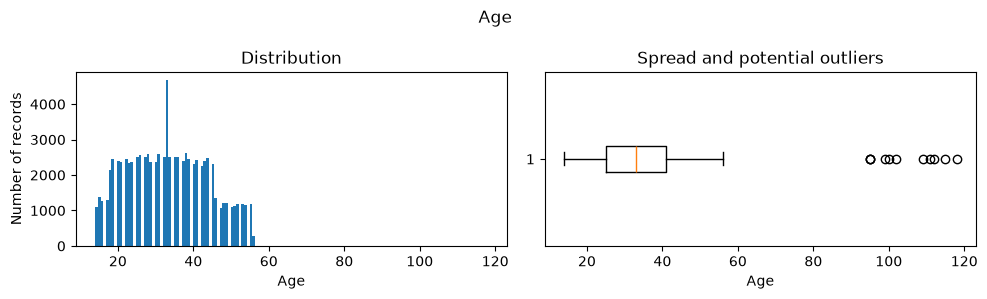

,Annual_Income
count,87500.00
mean,178529.29
std,1447458.76
min,7005.93
1%,7534.18
25%,19457.50
50%,37579.18
75%,72814.86
99%,404766.37
max,24198062.00


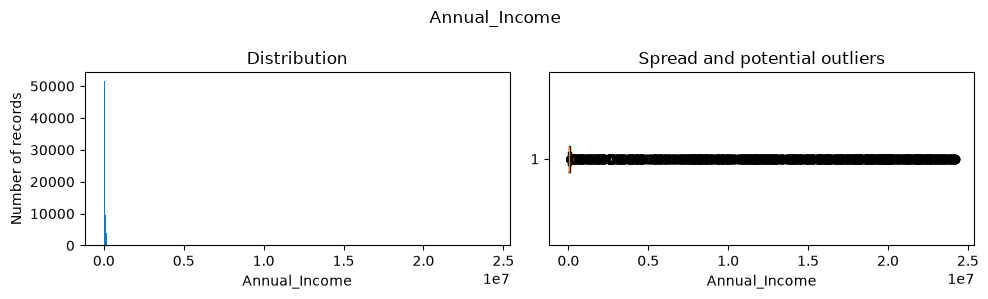

,Monthly_Inhand_Salary
count,87500.00
mean,4030.83
std,2963.36
min,303.65
1%,552.17
25%,1791.24
50%,3095.90
75%,5373.57
99%,13599.00
max,15204.63


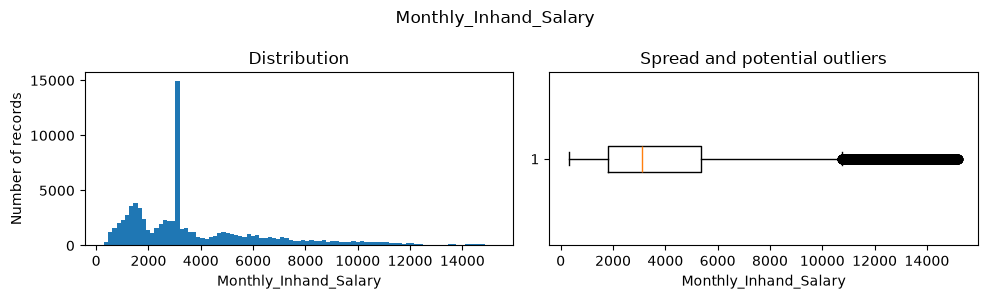

,Num_Bank_Accounts
count,87500.00
mean,17.11
std,117.84
min,0.00
1%,0.00
25%,3.00
50%,6.00
75%,7.00
99%,441.01
max,1798.00


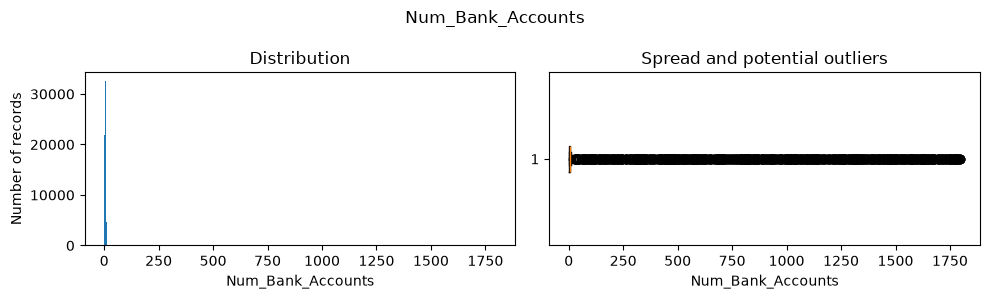

,Num_Credit_Card
count,87500.00
mean,22.37
std,128.63
min,0.00
1%,1.00
25%,4.00
50%,5.00
75%,7.00
99%,841.01
max,1499.00


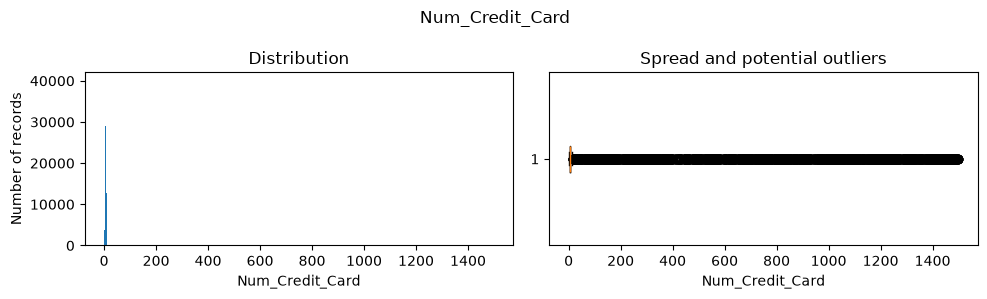

,Interest_Rate
count,87500.00
mean,72.36
std,466.10
min,1.00
1%,1.00
25%,8.00
50%,13.00
75%,20.00
99%,2863.04
max,5797.00


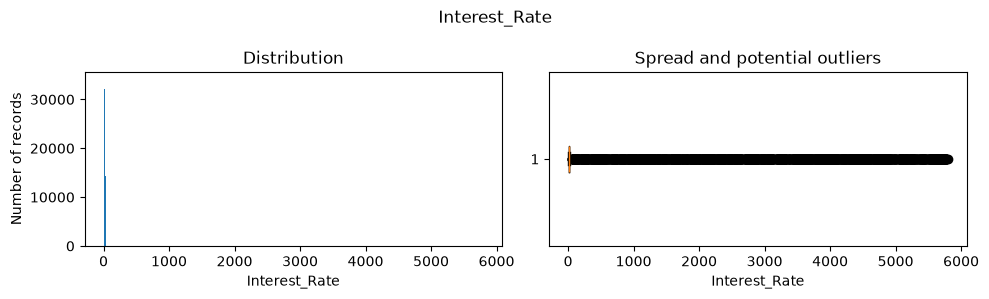

,Num_of_Loan
count,87500.00
mean,6.97
std,58.78
min,0.00
1%,0.00
25%,2.00
50%,3.00
75%,5.00
99%,9.00
max,1496.00


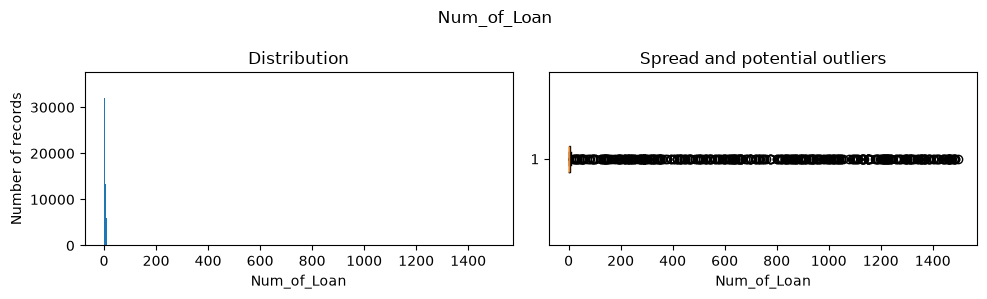

,Delay_from_due_date
count,87500.00
mean,21.07
std,14.86
min,-5.00
1%,0.00
25%,10.00
50%,18.00
75%,28.00
99%,61.00
max,67.00


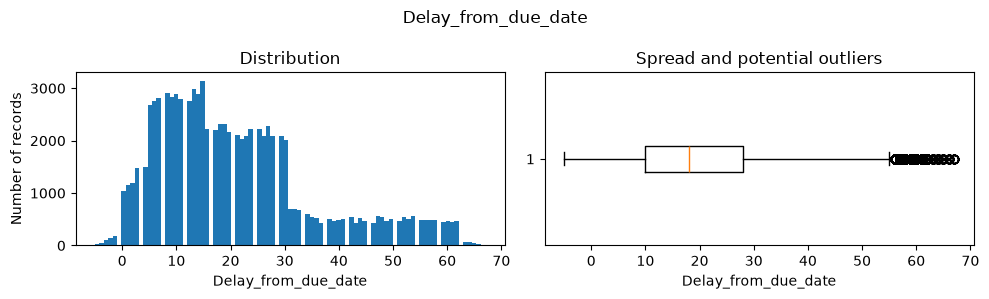

,Num_of_Delayed_Payment
count,87500.00
mean,29.56
std,216.34
min,0.00
1%,0.00
25%,9.00
50%,14.00
75%,18.00
99%,27.00
max,4397.00


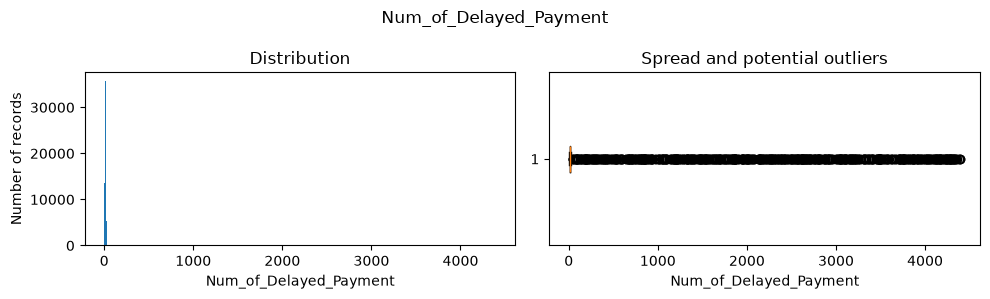

,Changed_Credit_Limit
count,87500.00
mean,10.37
std,6.72
min,-6.48
1%,-1.45
25%,5.41
50%,9.40
75%,14.65
99%,28.77
max,36.49


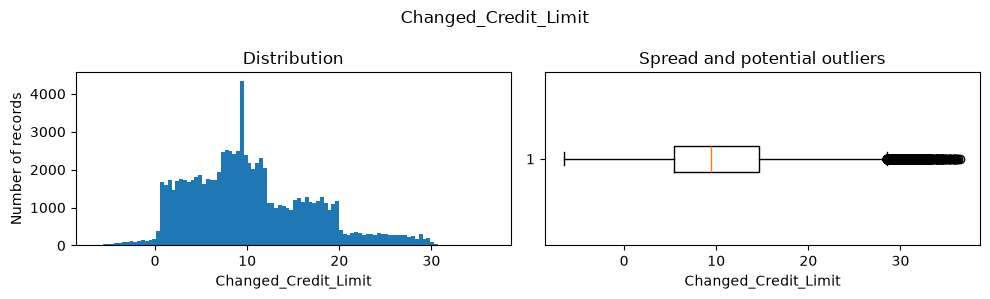

,Num_Credit_Inquiries
count,87500.00
mean,27.51
std,192.86
min,0.00
1%,0.00
25%,3.00
50%,5.00
75%,8.00
99%,1078.06
max,2597.00


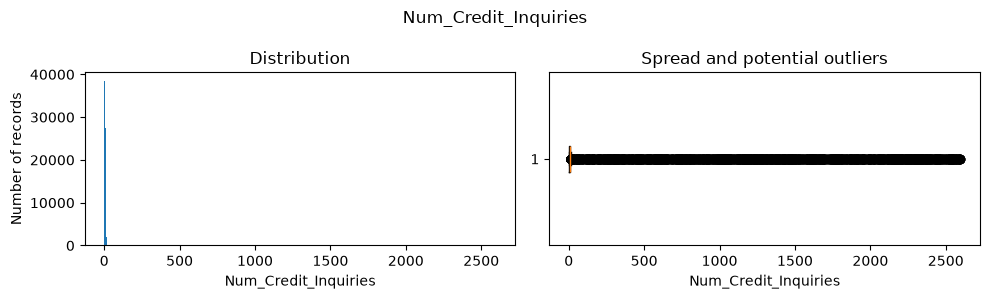

,Outstanding_Debt
count,87500.00
mean,1426.22
std,1155.13
min,0.23
1%,27.63
25%,566.07
50%,1166.16
75%,1945.96
99%,4806.97
max,4998.07


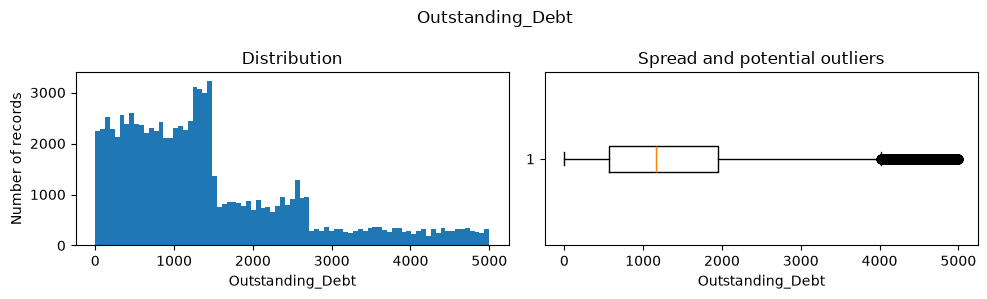

,Credit_Utilization_Ratio
count,87500.00
mean,32.28
std,5.11
min,20.00
1%,22.74
25%,28.05
50%,32.29
75%,36.48
99%,42.44
max,50.00


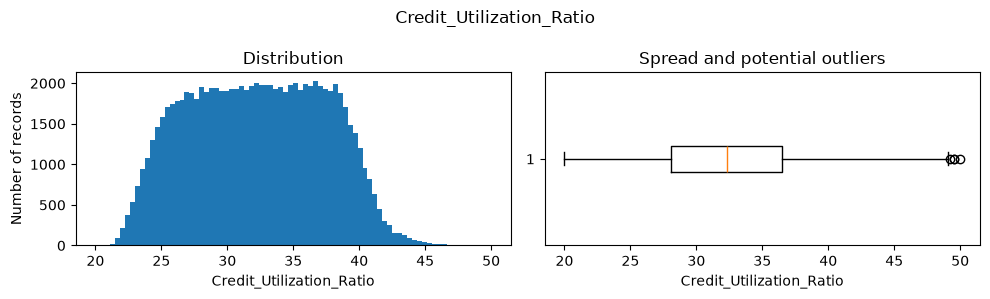

,Credit_History_Age
count,87500.00
mean,220.56
std,95.15
min,1.00
1%,17.00
25%,153.00
50%,219.00
75%,291.00
99%,395.00
max,403.00


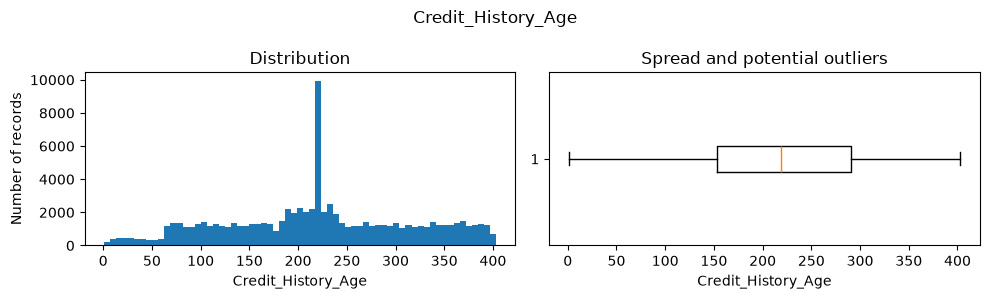

,Total_EMI_per_month
count,87500.00
mean,1390.94
std,8268.89
min,0.00
1%,0.00
25%,30.14
50%,68.73
75%,159.80
99%,55843.18
max,82331.00


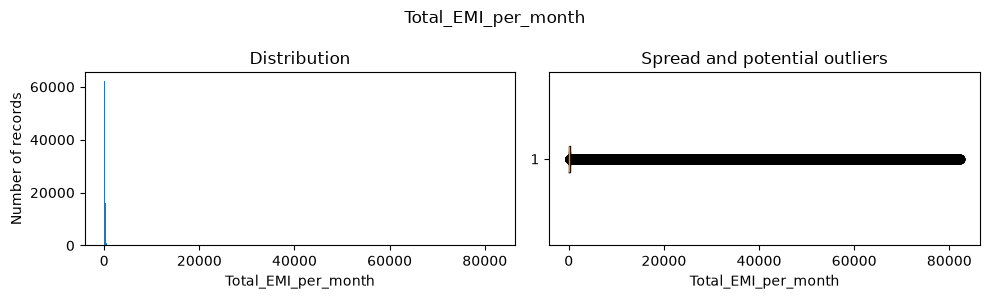

,Amount_invested_monthly
count,87500.00
mean,614.92
std,1999.21
min,0.00
1%,16.99
25%,77.15
50%,136.08
75%,255.85
99%,10000.00
max,10000.00


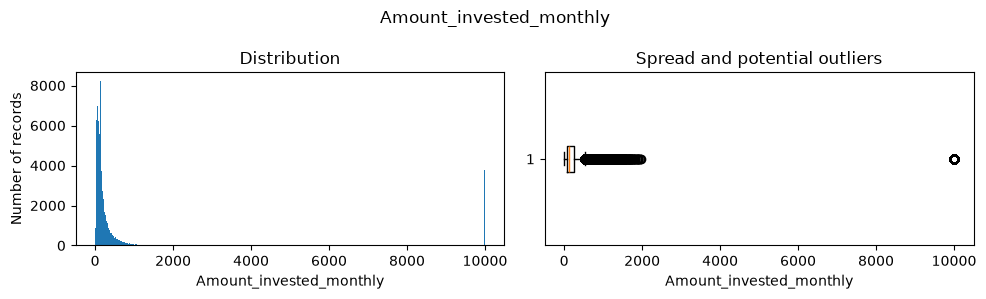

,Monthly_Balance
count,87500.00
mean,401.65
std,212.92
min,0.01
1%,67.83
25%,270.89
50%,336.41
75%,467.54
99%,1139.69
max,1602.04


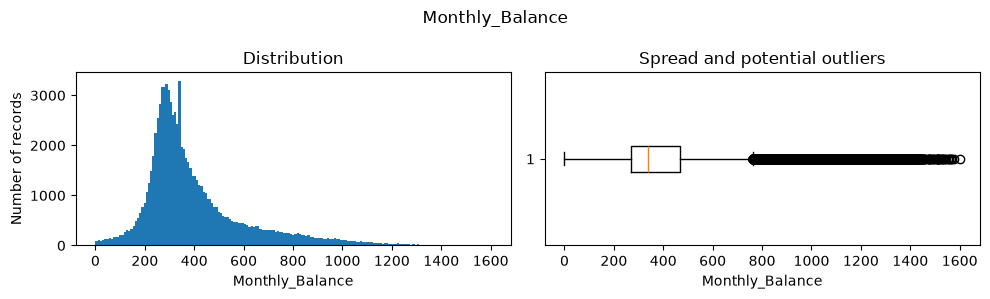

In [33]:
for col in x_train.select_dtypes(include="number").columns:
    inspect_numeric(x_train, col)

**Main Univariate Observations**

- Some income, loan count, interest rate and EMI values are way higher than the rest. Could be real entries or errors.
- Monthly investment has lots of values at exactly 10,000. May be an artificial cap where all values above 10,000 got capped to it. The values used to be `'__10000__'` before they were cleaned so maybe that was a placeholder for high investments.
- Ages sit mainly around the 14-56 range as stated with sparse entries reaching up to 118. As expected.
- Filling missing values with medians has made some clear spikes in the plots.
- Most cols contain outliers, keeping for now but will need to be investigated and dealt with as they may heavily affect clustering.

#### Outlier Detection

In [34]:
# Using IQR to flag any far values
numeric_data = x_train.select_dtypes(include="number")

q1 = numeric_data.quantile(0.25)
q3 = numeric_data.quantile(0.75)
iqr = q3 - q1

# Bounds
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

below = numeric_data.lt(lower).sum()
above = numeric_data.gt(upper).sum()

# Build summary
outlier_summary = pd.DataFrame({
    "lower_bound": lower,
    "upper_bound": upper,
    "below": below,
    "above": above,
    "total_flagged": below+above,
    "flagged_%": (below+above) / len(numeric_data) * 100
}).sort_values("flagged_%", ascending=False)
display(outlier_summary)

,lower_bound,upper_bound,below,above,total_flagged,flagged_%
Amount_invested_monthly,-190.898298,523.900819,0,9467,9467,10.819429
Monthly_Balance,-24.075263,762.501737,0,6899,6899,7.884571
Total_EMI_per_month,-164.353887,354.291287,0,5881,5881,6.721143
Outstanding_Debt,-1503.7625,4015.7975,0,4613,4613,5.272
Monthly_Inhand_Salary,-3582.26401,10747.073073,0,3822,3822,4.368
Delay_from_due_date,-17.0,55.0,0,3498,3498,3.997714
Annual_Income,-60578.54,152850.9,0,2437,2437,2.785143
Num_Credit_Inquiries,-4.5,15.5,0,2011,2011,2.298286
Num_Credit_Card,-0.5,11.5,0,1975,1975,2.257143
Interest_Rate,-10.0,38.0,0,1764,1764,2.016


IQR check found many values outside the bounds for multiple columns. Because they may be legitimate records and we can't to be sure, I will keep the records as is. If clustering seems strongly shifted by these extremes later, I may end up pruning many of these outliers.

#### Bivariate Analysis and Correlation

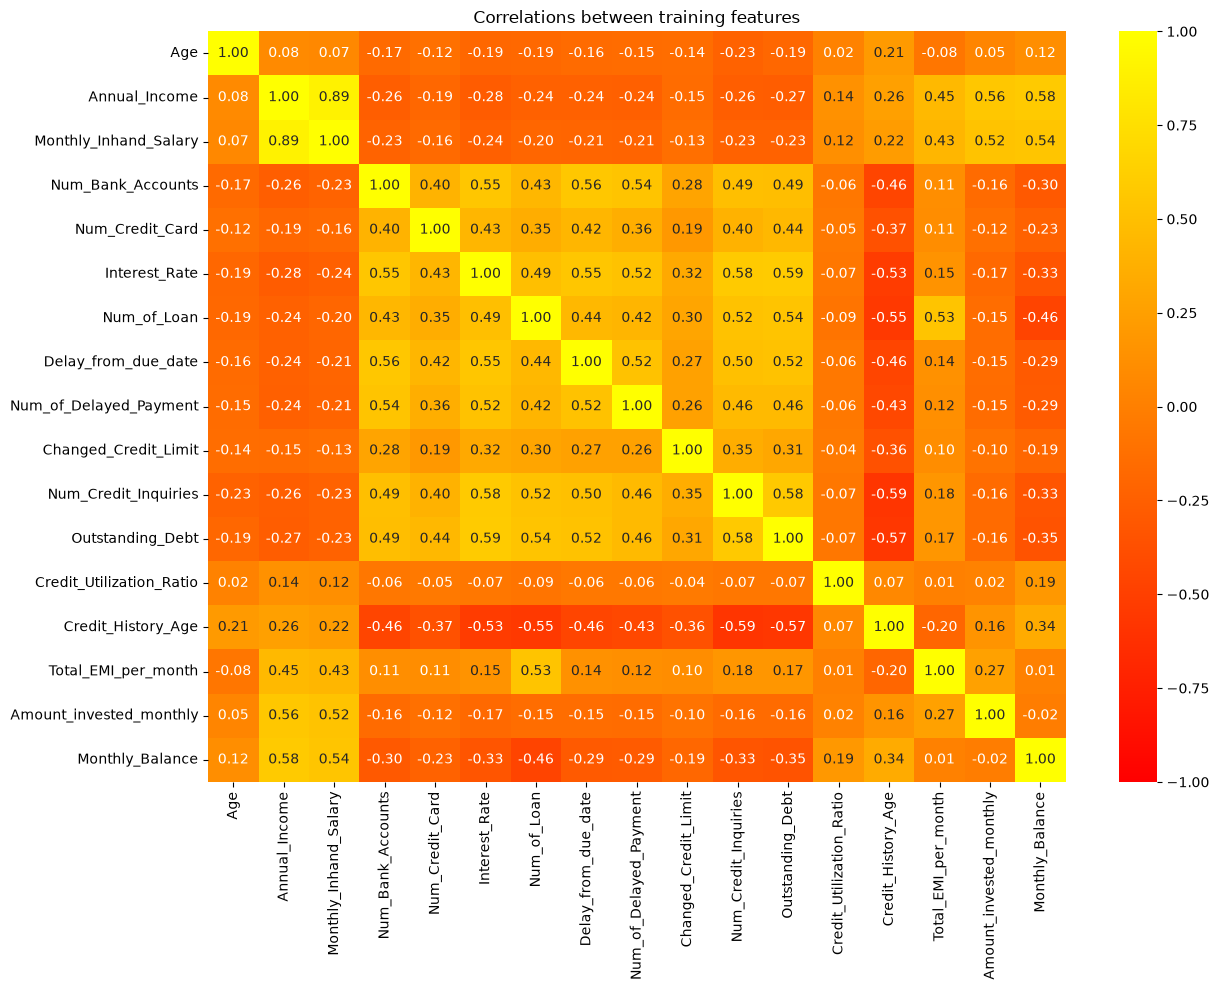

In [35]:
# Correlation
numeric_data = x_train.select_dtypes(include="number")
# Spearman handles large values better apparently by not weighting them hard
correlations = numeric_data.corr(method="spearman")

plt.figure(figsize=(13, 10))
sns.heatmap(
    correlations,
    cmap="autumn",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f"
)

plt.title("Correlations between training features")
plt.tight_layout()
plt.show()

**Main Correlation Observations**

- Annual income and monthly salary have the strongest correlation at 0.89. They provide pretty much the same information just within different time frames.
- Higher income tends to correlate with higher balances and investments.
- Higher debt tends to correlate with higher interest rates.
- Longer credit histories tend to correlate with lower debt and less credit inquiries.
- Credit utilisation has weak correlations with most other features.

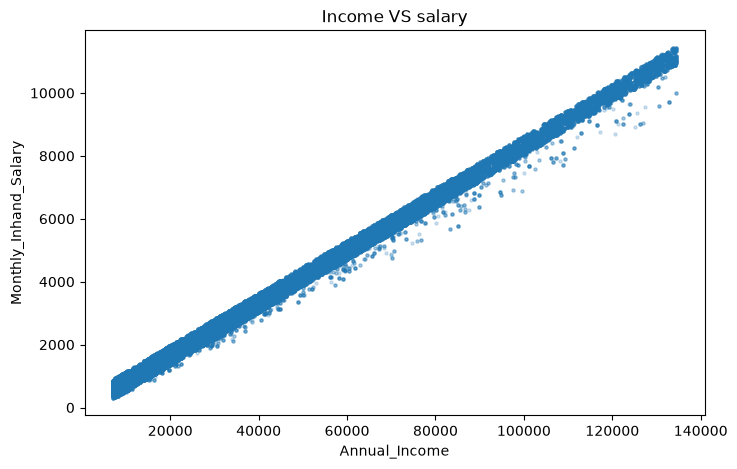

In [36]:
# Annual_Income VS Monthly_Inhand_Salary

# Ignoring our imputed median to see relationship clearer
observed = x_train.loc[
    train_data.loc[x_train.index, "Monthly_Inhand_Salary"].notna()
]

# Ignoring highest 5% of incomes, too far and sparse, makes plot squished
zoomed = observed[
    observed["Annual_Income"] <= observed["Annual_Income"].quantile(0.95)
]

# Scatterplot
zoomed.plot.scatter(
    x="Annual_Income",
    y="Monthly_Inhand_Salary",
    alpha=0.2,
    s=5,
    figsize=(8,5),
    title="Income VS salary"
)
plt.ticklabel_format(style="plain", axis="both")
plt.show()

Annual income and monthly salary follow a pretty much straight line relationship. They clearly contain similar information so one could possibly be dropped for clustering.

This plot excludes the earlier imputations and the highest 5% of incomes. The line also suggests that instead of median imputation for missing salaries we may be able to predict the missing salaries from income. May be worth testing later.

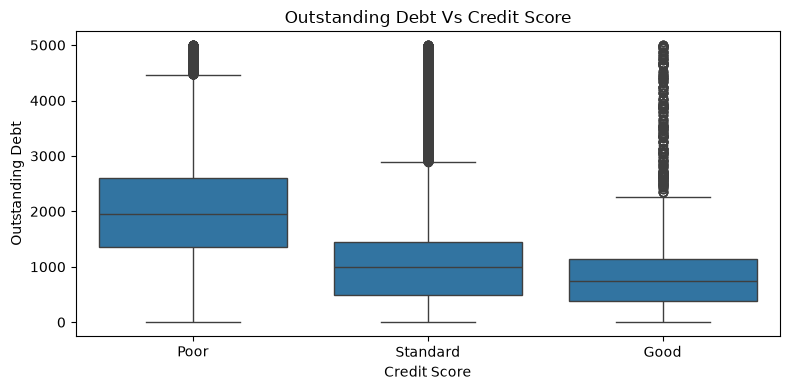

In [37]:
# Checking if debt levels differ cleanly between poor, standard and good credit scores.

debt_by_score = x_train[["Outstanding_Debt"]].copy()
debt_by_score["Credit_Score"] = y_train

# Plotting debt distribution across the 3 groups
plt.figure(figsize=(8,4))
sns.boxplot(
    data=debt_by_score,
    x="Credit_Score",
    y="Outstanding_Debt",
    order=["Poor", "Standard", "Good"]
)
plt.title("Outstanding Debt Vs Credit Score")
plt.xlabel("Credit Score")
plt.ylabel("Outstanding Debt")
plt.tight_layout()
plt.show()

Poor credit scores generally have higher outstanding debt than standard and good scores. However, there is an overlap between groups so debt alone cannot separate them. Debt should still be a good classification candidate to use.  

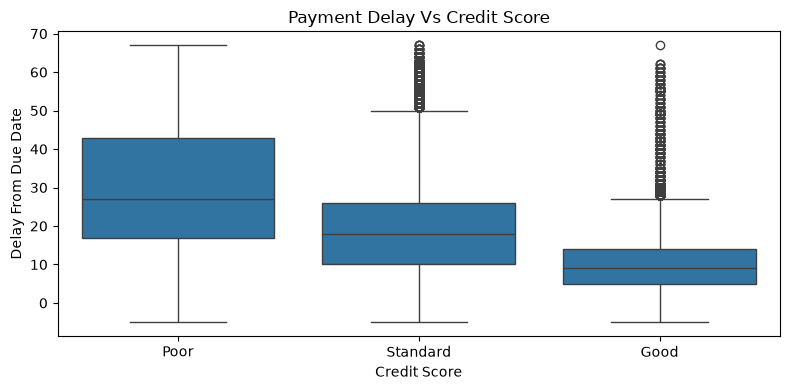

In [38]:
# Checking if payment delays differ between credit score groups.

delay_by_score = x_train[["Delay_from_due_date"]].copy()
delay_by_score["Credit_Score"] = y_train

plt.figure(figsize=(8, 4))
sns.boxplot(
    data=delay_by_score,
    x="Credit_Score",
    y="Delay_from_due_date",
    order=["Poor", "Standard", "Good"],
)
plt.title("Payment Delay Vs Credit Score")
plt.xlabel("Credit Score")
plt.ylabel("Delay From Due Date")
plt.tight_layout()
plt.show()

Payment delays seem to follow the same trend as outstanding debt, generally longer for poor credit scores and shorter for good scores. The groups still overlap so delay alone cannot determine the score but seems to also be a good classification candidate.

Credit_Score,Poor,Standard,Good
Credit_Mix,,,
Bad,60.6,38.0,1.3
Good,15.9,34.8,49.3
Standard,21.2,73.9,4.8
Unknown,29.3,52.9,17.8


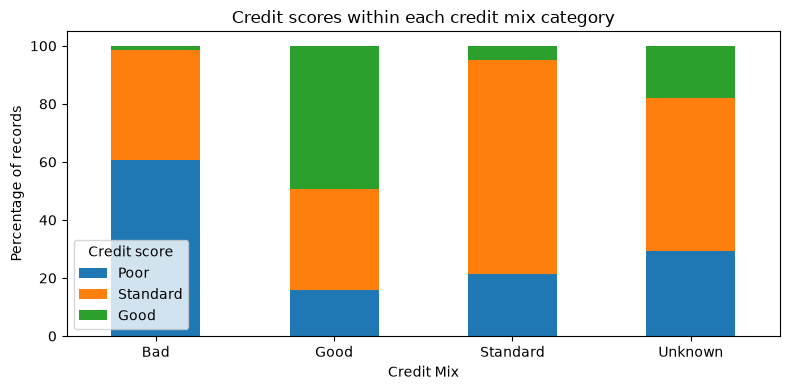

In [39]:
# Checking if credit mix distinguishes the credit score groups
mix_by_score = pd.crosstab(
    x_train["Credit_Mix"],
    y_train,
    normalize="index",
).reindex(columns=["Poor", "Standard", "Good"]) * 100

# stacked bar per credit mix category
display(mix_by_score.round(1))
mix_by_score.plot.bar(stacked=True, figsize=(8,4))

plt.title("Credit scores within each credit mix category")
plt.xlabel("Credit Mix")
plt.ylabel("Percentage of records")
plt.xticks(rotation=0)
plt.legend(title="Credit score")
plt.tight_layout()
plt.show()

The proportions of credit scores within the credit mix groups differ. Bad credit mix mostly has poor scores, while good credit mix has a much larger portion of the good scores. Credit seems like it will be helpful for the classification.

#### Rebuilding CSVs
At this point I realised the clustering and classification need to be done in separate notebooks. I'm going to rebuild the required CSVs here for use in the respective notebooks.

In [40]:
output_dir = proj_root / "data"

# Adding classification labels back for classification csv
classification_train = x_train.copy()
classification_train["Credit_Score"] = y_train
classification_val = x_val.copy()
classification_val["Credit_Score"] = y_val

# Saving classification csvs
classification_train.to_csv(output_dir/"Classification_train.csv", index=False)
classification_val.to_csv(output_dir/"Classification_val.csv", index=False)
test_clean.to_csv(output_dir / "Classification_test.csv", index=False)

# Merge val back into train for clustering
clustering_train = pd.concat([x_train, x_val]).sort_index()

# Saving labels separately for interpreting clusters later
clustering_reference = clustering_train[["ID", "Customer_ID"]].copy()
clustering_reference["Credit_SCore"] = pd.concat([y_train, y_val]).reindex(clustering_train.index)

# Save clustering inputs and reference info
clustering_train.to_csv(output_dir / "clustering_train.csv", index=False)
test_clean.to_csv(output_dir / "clustering_test.csv", index=False)
clustering_reference.to_csv(output_dir / "clustering_reference.csv", index=False)

# Sizes
print(f"Classification training: {classification_train.shape}")
print(f"Classification validation: {classification_val.shape}")
print(f"Clustering training: {clustering_train.shape}")
print(f"Test: {test_clean.shape}")

Classification training: (87500, 28)
Classification validation: (12500, 28)
Clustering training: (100000, 27)
Test: (50000, 27)
